In [88]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

df = pd.read_csv('/content/data.csv')
df.head()

df.drop(columns=['id','Unnamed: 32'],inplace=True)
df.head()


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [89]:
X_train,X_test,y_train,y_test=train_test_split(df.iloc[:,1:], df.iloc[:,0],test_size=0.2,random_state=2)

In [90]:
scaler=StandardScaler()
scaler.fit_transform(X_train)
scaler.fit_transform(X_test)

array([[-0.08700339, -1.47192915, -0.10537391, ..., -0.26629174,
        -1.09776353, -0.65597459],
       [ 0.19989092,  0.03577342,  0.1706179 , ...,  0.44844054,
         0.06066588,  0.02108157],
       [-1.28858427, -0.21847659, -1.30667757, ..., -1.41981535,
         0.19788632, -0.31050377],
       ...,
       [ 0.67523542,  0.61546345,  0.70329853, ...,  1.36221218,
         1.000987  ,  0.62759948],
       [ 0.20832899,  1.5866985 ,  0.10942329, ..., -1.35965118,
        -1.95719681, -1.62740299],
       [ 0.78774299,  0.03068842,  0.84293725, ...,  2.03773974,
         0.27299646,  0.34822356]])

In [42]:
knn=KNeighborsClassifier(n_neighbors=3)

In [43]:
knn.fit(X_train,y_train)


KNeighborsClassifier(n_neighbors=3)

In [91]:
y_pred=knn.predict(X_test)
accuracy_score(y_test,y_pred)

0.8859649122807017

In [26]:
scores=[]
for i in range(1,25):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train,y_train)
    y_pred=knn.predict(X_test)
    scores.append(accuracy_score(y_test,y_pred))

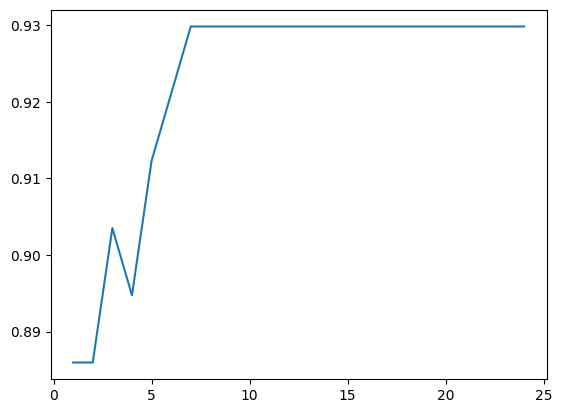

In [28]:
plt.plot(range(1,25),scores)

In [92]:
from collections import Counter

class MyKNN:
  def __init__(self,k=3):
    self.k=k
    self.X_train=None
    self.y_train=None

  def fit(self,X_train,y_train):
    self.X_train=np.array(X_train)
    self.y_train=np.array(y_train)



  def predict(self,X_test):
    predictions=[]

    for test_point in np.array(X_test):

      distances=[]

      for train_point in self.X_train:

        distance=np.linalg.norm(train_point - test_point)
        distances.append(distance)

      distances=np.array(distances)

      k_indices=np.argsort(distances)[self.k]
      k_labels=self.y_train[k_indices]

      most_common = Counter(k_labels).most_common(1)[0][0]
      predictions.append(most_common)

    return predictions


In [93]:
knn=MyKNN(3)
knn.fit(X_train,y_train)
y_pred=knn.predict(X_test)
accuracy_score(y_test,y_pred)

0.8859649122807017